# HAM10000 Skin Lesion Classification

## 02 - Data Preprocessing

### Objective
Prepare the HAM10000 dataset for deep learning model training.

### Tasks
1. Load the explored dataset.
2. Inspect missing values.
3. Handle missing metadata.
4. Encode target labels.
5. Perform lesion-wise train-validation-test splitting.
6. Verify class distributions.
7. Prepare image data generators.

In [1]:
# Import libraries for data preprocessing

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Set visualization style
sns.set_style("whitegrid")

# Set random seed for reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Define project directories

PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

# Create output directory if it does not exist
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Define dataset path
EXPLORED_DATA_PATH = OUTPUT_DIR / "HAM10000_explored.csv"

# Define image configuration
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

# Define class labels
CLASS_NAMES = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]

print("Configuration completed!")
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

Configuration completed!
Image size: (224, 224)
Batch size: 32


In [3]:
# Load the explored metadata generated in Notebook 01

df = pd.read_csv(EXPLORED_DATA_PATH)

# Display the first five records
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,..\data\HAM10000_images_part_1\ISIC_0027419.jpg
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,..\data\HAM10000_images_part_1\ISIC_0025030.jpg
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,..\data\HAM10000_images_part_1\ISIC_0026769.jpg
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,..\data\HAM10000_images_part_1\ISIC_0025661.jpg
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,..\data\HAM10000_images_part_2\ISIC_0031633.jpg


In [4]:
# Display dataset dimensions

print("Dataset shape:", df.shape)

# Display column information
df.info()

# Display diagnostic class counts
print("\nClass distribution:")
print(df["dx"].value_counts())

Dataset shape: (10015, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  object 
 1   image_id      10015 non-null  object 
 2   dx            10015 non-null  object 
 3   dx_type       10015 non-null  object 
 4   age           9958 non-null   float64
 5   sex           10015 non-null  object 
 6   localization  10015 non-null  object 
 7   image_path    10015 non-null  object 
dtypes: float64(1), object(7)
memory usage: 626.1+ KB

Class distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [5]:
# Calculate missing values for each column

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": (
        missing_values / len(df)
    ) * 100
})

missing_summary.sort_values(
    by="Missing Count",
    ascending=False
)

,Missing Count,Missing Percentage
age,57,0.569146
lesion_id,0,0.000000
image_id,0,0.000000
dx,0,0.000000
dx_type,0,0.000000
sex,0,0.000000
localization,0,0.000000
image_path,0,0.000000


## Missing Value Handling

The age column may contain missing values.

We will replace missing age values using the median age.

The sex and localization columns are metadata features.
For this image classification baseline, they will not be
used as model inputs.

We will not remove images simply because optional
metadata values are missing.

In [6]:
# Create a copy of the original DataFrame

df_processed = df.copy()

# Convert age to numeric values
df_processed["age"] = pd.to_numeric(
    df_processed["age"],
    errors="coerce"
)

# Calculate median age
median_age = df_processed["age"].median()

# Fill missing age values
df_processed["age"] = df_processed["age"].fillna(
    median_age
)

# Remove records with missing target labels,
# image IDs, or image paths
df_processed = df_processed.dropna(
    subset=["dx", "image_id", "image_path", "lesion_id"]
).copy()

# Remove records whose image files do not exist
df_processed = df_processed[
    df_processed["image_path"].apply(
        lambda path: Path(path).is_file()
    )
].copy()

print("Shape after preprocessing:", df_processed.shape)
print("Missing age values:", df_processed["age"].isnull().sum())

Shape after preprocessing: (10015, 8)
Missing age values: 0


In [7]:
# Create a label encoder

label_encoder = LabelEncoder()

# Fit encoder using the predefined class order
label_encoder.fit(CLASS_NAMES)

# Convert diagnostic labels into integer values
df_processed["label"] = label_encoder.transform(
    df_processed["dx"]
)

# Display class-to-number mapping
class_mapping = {
    class_name: int(label_encoder.transform([class_name])[0])
    for class_name in CLASS_NAMES
}

print("Class mapping:")
print(class_mapping)

df_processed[["dx", "label"]].head(10)

Class mapping:
{'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


,dx,label
0,bkl,2
1,bkl,2
2,bkl,2
3,bkl,2
4,bkl,2
5,bkl,2
6,bkl,2
7,bkl,2
8,bkl,2
9,bkl,2


In [8]:
# Count unique lesions in the dataset

print(
    "Total images:",
    len(df_processed)
)

print(
    "Unique lesions:",
    df_processed["lesion_id"].nunique()
)

print(
    "Images per lesion:"
)

df_processed["lesion_id"].value_counts().describe()

Total images: 10015
Unique lesions: 7470
Images per lesion:


count    7470.000000
mean        1.340696
std         0.633970
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         6.000000
Name: count, dtype: float64

In [9]:
# Create stratified group folds.
# Grouping by lesion_id keeps images from the same lesion together.

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Select one fold for testing
train_val_indices, test_indices = next(
    splitter.split(
        df_processed,
        y=df_processed["label"],
        groups=df_processed["lesion_id"]
    )
)

# Create train-validation pool and test DataFrames
train_val_df = df_processed.iloc[
    train_val_indices
].copy()

test_df = df_processed.iloc[
    test_indices
].copy()

print("Train + Validation:", train_val_df.shape)
print("Test:", test_df.shape)

Train + Validation: (8001, 9)
Test: (2014, 9)


In [10]:
# Split the remaining data into training and validation sets.
# Four folds provide approximately 75% train and 25% validation
# within the train-validation pool.

splitter_val = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=RANDOM_STATE
)

train_indices, val_indices = next(
    splitter_val.split(
        train_val_df,
        y=train_val_df["label"],
        groups=train_val_df["lesion_id"]
    )
)

# Create final splits
train_df = train_val_df.iloc[train_indices].copy()
val_df = train_val_df.iloc[val_indices].copy()

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

Training samples: 5942
Validation samples: 2059
Testing samples: 2014


In [11]:
# Extract unique lesion IDs from each split

train_lesions = set(train_df["lesion_id"])
val_lesions = set(val_df["lesion_id"])
test_lesions = set(test_df["lesion_id"])

# Check for overlapping lesions

print(
    "Train-Validation overlap:",
    len(train_lesions & val_lesions)
)

print(
    "Train-Test overlap:",
    len(train_lesions & test_lesions)
)

print(
    "Validation-Test overlap:",
    len(val_lesions & test_lesions)
)

Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0


In [12]:
# Create a summary of dataset splits

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Samples": [
        len(train_df),
        len(val_df),
        len(test_df)
    ]
})

split_summary["Percentage"] = (
    split_summary["Samples"] /
    len(df_processed)
) * 100

split_summary

,Dataset,Samples,Percentage
0,Training,5942,59.331003
1,Validation,2059,20.559161
2,Testing,2014,20.109835


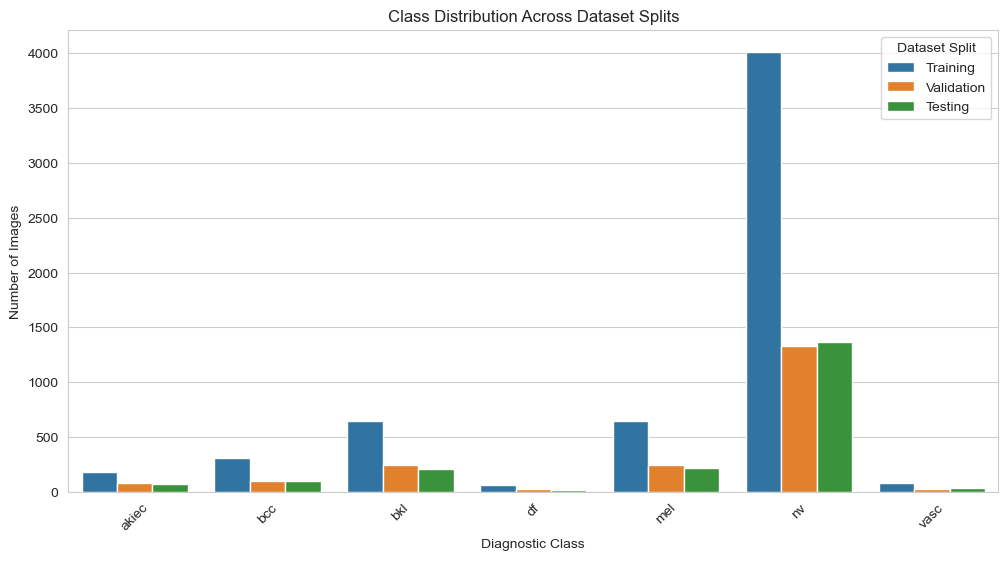

In [13]:
# Add split labels to each DataFrame

train_df["split"] = "Training"
val_df["split"] = "Validation"
test_df["split"] = "Testing"

# Combine all splits for visualization
combined_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Plot class distribution
plt.figure(figsize=(12, 6))

sns.countplot(
    data=combined_df,
    x="dx",
    hue="split",
    order=CLASS_NAMES
)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Diagnostic Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.legend(title="Dataset Split")

plt.show()

## Image Data Generators

We will use ImageDataGenerator to load images in batches.

Training data will use augmentation:
- Rotation
- Horizontal flipping
- Vertical flipping
- Zoom
- Width and height shifts

Validation and testing data will not use augmentation.

All images will be rescaled to the range [0, 1].

In [14]:
# Create training data generator with augmentation

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    vertical_flip=True
)

# Create validation and test generators without augmentation

validation_datagen = ImageDataGenerator(
    rescale=1.0 / 255
)

test_datagen = ImageDataGenerator(
    rescale=1.0 / 255
)

print("Image data generators created successfully!")

Image data generators created successfully!


In [15]:
# Load training images in batches

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=True,
    seed=RANDOM_STATE
)

Found 5942 validated image filenames belonging to 7 classes.


In [16]:
# Load validation images in batches

validation_generator = validation_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

Found 2059 validated image filenames belonging to 7 classes.


In [17]:
# Load test images in batches

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

Found 2014 validated image filenames belonging to 7 classes.


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 7)


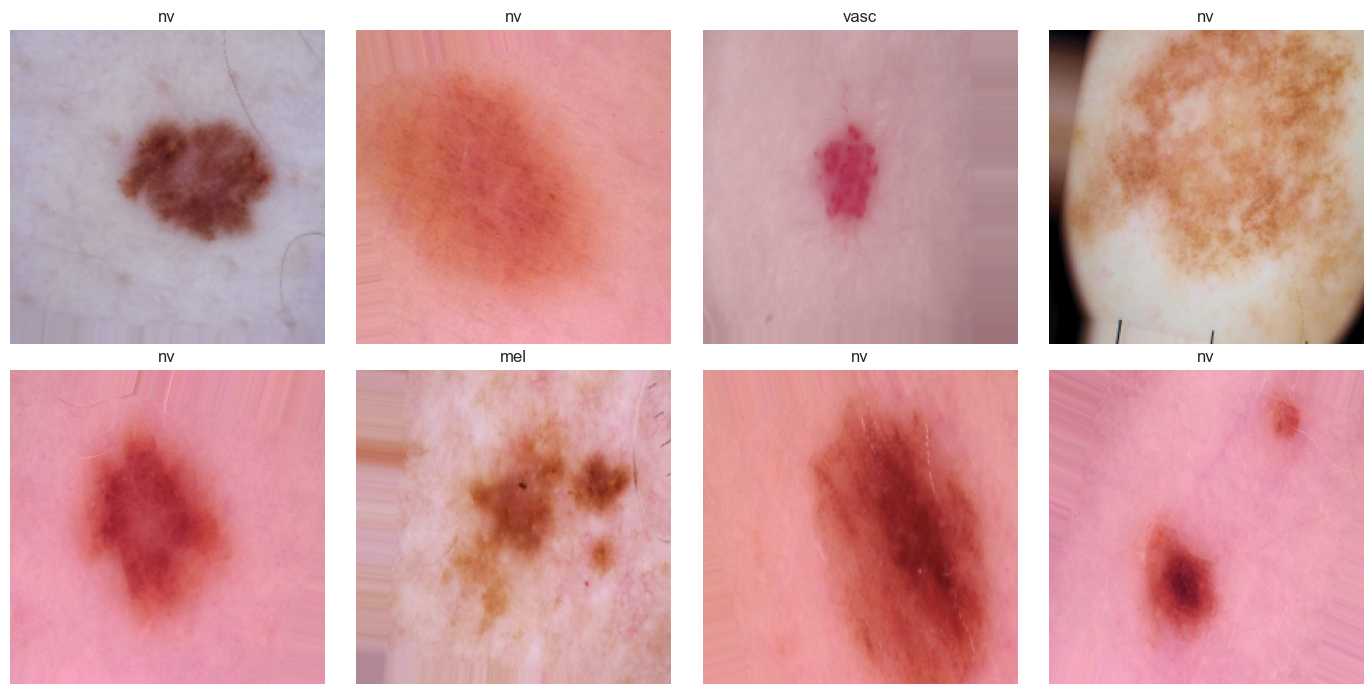

In [18]:
# Retrieve one batch from the training generator

images, labels = next(train_generator)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

# Display sample images
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for index, ax in enumerate(axes.flatten()):

    ax.imshow(images[index])

    class_index = np.argmax(labels[index])
    class_name = CLASS_NAMES[class_index]

    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [19]:
# Save the three dataset splits

train_df.to_csv(
    OUTPUT_DIR / "train.csv",
    index=False
)

val_df.to_csv(
    OUTPUT_DIR / "validation.csv",
    index=False
)

test_df.to_csv(
    OUTPUT_DIR / "test.csv",
    index=False
)

print("Train, validation, and test CSV files saved!")

Train, validation, and test CSV files saved!


In [20]:
# Display final preprocessing summary

print("PREPROCESSING SUMMARY")
print("---------------------")

print("Total images:", len(df_processed))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("Number of classes:", len(CLASS_NAMES))
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

print("Train generator batches:", len(train_generator))
print("Validation generator batches:", len(validation_generator))
print("Test generator batches:", len(test_generator))

PREPROCESSING SUMMARY
---------------------
Total images: 10015
Training images: 5942
Validation images: 2059
Testing images: 2014
Number of classes: 7
Image size: (224, 224)
Batch size: 32
Train generator batches: 186
Validation generator batches: 65
Test generator batches: 63


## Conclusion

The HAM10000 dataset has been preprocessed successfully.

- Missing age values were handled using median imputation.
- Diagnostic classes were encoded.
- Dataset splitting was performed using lesion groups.
- Data leakage between splits was checked.
- Training images use data augmentation.
- Validation and test images use only rescaling.
- Image generators were created for deep learning.

The dataset is now ready for CNN model training.

